# Scenario Detection

This notebook flags candidate harsh braking, rapid acceleration, abrupt jerk, and lane-change observations from the feature-engineered trajectory data. The rules are transparent screening thresholds; the resulting records need contextual review before being treated as real-world safety events.

In [39]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

repo_root = Path.cwd()
if not (repo_root / "src").is_dir():
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.python import data_loader
from src.python import scenario_detection
import importlib
importlib.reload(scenario_detection)

sns.set_theme(style="whitegrid")


## 1. Load and inspect the feature-engineered dataset

In [40]:
input_path = repo_root / "data" / "processed" / "featured_trajectories.csv"
df = data_loader.load_data(input_path)
print(f"Loaded {len(df):,} observations from {input_path}")
display(df.head())
print("Columns:", list(df.columns))


Loaded 137,928 observations from c:\Users\nasty\Desktop\PetProjects\vehicle-trajectory-analytics\data\processed\featured_trajectories.csv


,id,time,xloc_kf,yloc_kf,lane_kf,speed_kf,acceleration_kf,length_smoothed,width_smoothed,type_most_common,acc,run_index,speed_kmh,jerk_mps3,abs_acceleration
0,143,38.1,1778.595,135.24,-5,23.15,0.0,5.45,2.67,small-vehicle,no,5,83.34,NaN,0.0
1,143,38.2,1780.910,135.60,-5,23.15,-0.5,5.45,2.67,small-vehicle,no,5,83.34,-5.0,0.5
2,143,38.3,1783.225,135.97,-5,23.10,1.0,5.45,2.67,small-vehicle,no,5,83.16,15.0,1.0
3,143,38.4,1785.535,136.33,-5,23.20,-1.0,5.45,2.67,small-vehicle,no,5,83.52,-20.0,1.0
4,143,38.5,1787.855,136.70,-5,23.10,1.0,5.45,2.67,small-vehicle,no,5,83.16,20.0,1.0


Columns: ['id', 'time', 'xloc_kf', 'yloc_kf', 'lane_kf', 'speed_kf', 'acceleration_kf', 'length_smoothed', 'width_smoothed', 'type_most_common', 'acc', 'run_index', 'speed_kmh', 'jerk_mps3', 'abs_acceleration']


## 2. Inspect acceleration and jerk distributions

The acceleration percentiles help select provisional tail cutoffs. Jerk is noisy because it is calculated from frame-to-frame acceleration changes at 0.1-second intervals, so this notebook uses the 99th percentile of absolute jerk as a data-derived screening threshold.

In [41]:
acceleration_summary = df["acceleration_kf"].describe(
    percentiles=[0.01, 0.05, 0.10, 0.90, 0.95, 0.99]
)
display(acceleration_summary.to_frame(name="acceleration_m_s2"))


,acceleration_m_s2
count,137928.000000
mean,0.041181
std,1.555288
min,-22.000000
1%,-5.000000
5%,-2.000000
10%,-1.000000
90%,1.500000
95%,2.000000
99%,5.000000


In [42]:
if "jerk_mps3" not in df.columns:
    grouped = df.groupby(["run_index", "id"], sort=False)
    dt = grouped["time"].diff()
    df["jerk_mps3"] = grouped["acceleration_kf"].diff() / dt.where(dt > 0)

jerk_summary = df["jerk_mps3"].describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
)
display(jerk_summary.to_frame(name="jerk_m_s3"))


,jerk_m_s3
count,137216.000000
mean,0.003727
std,21.159341
min,-260.000000
1%,-65.000000
5%,-30.000000
50%,0.000000
95%,30.000000
99%,65.000000
max,260.000000


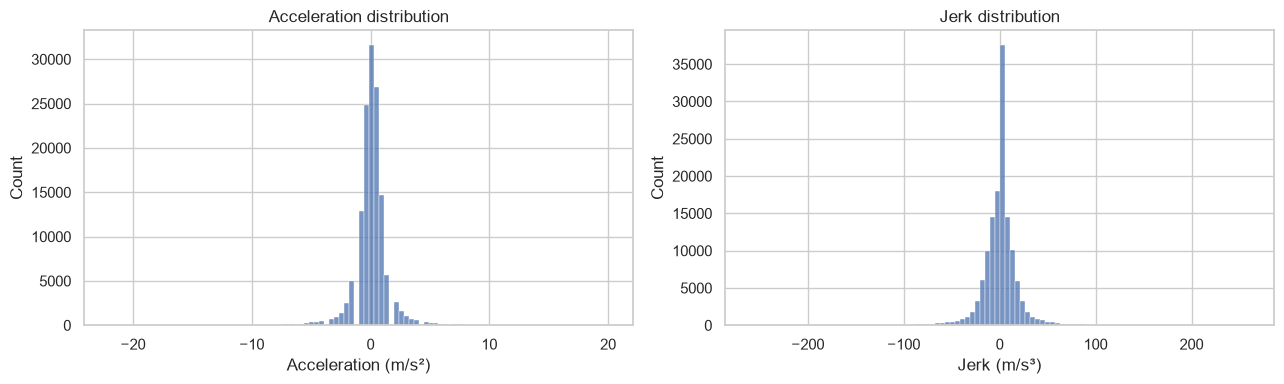

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="acceleration_kf", bins=100, ax=axes[0])
axes[0].set(title="Acceleration distribution", xlabel="Acceleration (m/s²)")
sns.histplot(data=df, x="jerk_mps3", bins=100, ax=axes[1])
axes[1].set(title="Jerk distribution", xlabel="Jerk (m/s³)")
plt.tight_layout()
plt.show()


## 3. Set provisional screening thresholds

Use −3 m/s² for harsh-braking candidates and +3 m/s² for rapid-acceleration candidates. These sit beyond the central acceleration range in the current exploration. Abrupt jerk uses the 99th percentile of absolute jerk. These are candidate filters, not externally validated definitions.

In [44]:
BRAKING_THRESHOLD_M_S2 = -3.0
ACCELERATION_THRESHOLD_M_S2 = 3.0
JERK_THRESHOLD_M_S3 = float(df["jerk_mps3"].abs().quantile(0.99))
MAX_LANE_CHANGE_GAP_SECONDS = 0.5

print(f"Harsh braking: acceleration <= {BRAKING_THRESHOLD_M_S2:g} m/s²")
print(f"Rapid acceleration: acceleration >= {ACCELERATION_THRESHOLD_M_S2:g} m/s²")
print(f"Abrupt jerk: |jerk| >= {JERK_THRESHOLD_M_S3:.2f} m/s³ (99th percentile)")
print(f"Lane change: adjacent valid lane labels differ within {MAX_LANE_CHANGE_GAP_SECONDS:g} s")


Harsh braking: acceleration <= -3 m/s²
Rapid acceleration: acceleration >= 3 m/s²
Abrupt jerk: |jerk| >= 85.00 m/s³ (99th percentile)
Lane change: adjacent valid lane labels differ within 0.5 s


## 4. Detect candidate observations

In [45]:
df_detected = scenario_detection.detect_scenarios(
    df,
    braking_threshold=BRAKING_THRESHOLD_M_S2,
    acceleration_threshold=ACCELERATION_THRESHOLD_M_S2,
    jerk_threshold=JERK_THRESHOLD_M_S3,
    max_lane_change_gap_seconds=MAX_LANE_CHANGE_GAP_SECONDS,
)

scenario_columns = [
    "candidate_harsh_braking",
    "candidate_rapid_acceleration",
    "candidate_abrupt_jerk",
    "candidate_lane_change",
]
observation_summary = pd.DataFrame({
    "candidate_observations": df_detected[scenario_columns].sum().astype(int),
    "share_of_all_observations": df_detected[scenario_columns].mean(),
})
display(observation_summary)


,candidate_observations,share_of_all_observations
candidate_harsh_braking,3966,0.028754
candidate_rapid_acceleration,4202,0.030465
candidate_abrupt_jerk,1388,0.010063
candidate_lane_change,215,0.001559


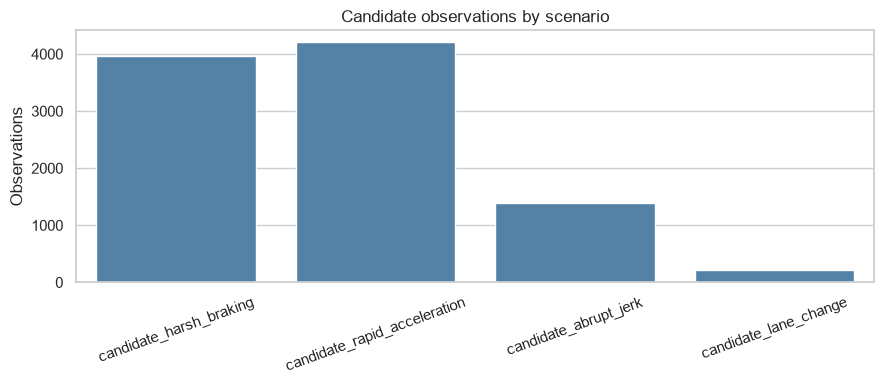

In [46]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_data = observation_summary["candidate_observations"].rename_axis("scenario").reset_index(name="observations")
sns.barplot(data=plot_data, x="scenario", y="observations", ax=ax, color="steelblue")
ax.set(title="Candidate observations by scenario", xlabel="", ylabel="Observations")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


## 5. Group candidate samples into event episodes

In [47]:
events = scenario_detection.summarize_events(df_detected)
if events.empty:
    print("No candidate event episodes were found with the selected thresholds.")
else:
    episode_summary = (
        events.groupby("scenario")
        .agg(episodes=("id", "size"), vehicles=("id", "nunique"), runs=("run_index", "nunique"))
        .sort_values("episodes", ascending=False)
    )
    display(episode_summary)
    display(events.head(20))


,episodes,vehicles,runs
scenario,,,
rapid_acceleration,3061,311,12
harsh_braking,2999,320,12
abrupt_jerk,747,170,12
lane_change,215,120,12


,run_index,id,scenario,start_time,end_time,event_time,duration_seconds,sample_count,min_acceleration_m_s2,max_acceleration_m_s2,max_abs_jerk_m_s3,lane_labels,previous_lane,new_lane
0,5,190,rapid_acceleration,37.0,37.0,NaN,0.0,1,3.5,3.5,10.0,-5,NaN,NaN
1,5,190,rapid_acceleration,37.2,37.2,NaN,0.0,1,3.5,3.5,20.0,-5,NaN,NaN
2,5,207,harsh_braking,33.7,33.7,NaN,0.0,1,-3.0,-3.0,5.0,-3,NaN,NaN
3,5,207,rapid_acceleration,36.9,36.9,NaN,0.0,1,3.0,3.0,35.0,-3,NaN,NaN
4,5,207,rapid_acceleration,37.2,37.2,NaN,0.0,1,4.5,4.5,25.0,-3,NaN,NaN
5,5,207,rapid_acceleration,37.4,37.4,NaN,0.0,1,3.0,3.0,35.0,-3,NaN,NaN
6,5,248,harsh_braking,27.4,27.4,NaN,0.0,1,-3.0,-3.0,10.0,-3,NaN,NaN
7,5,248,harsh_braking,27.7,28.0,NaN,0.3,4,-4.5,-3.0,30.0,-3,NaN,NaN
8,5,248,rapid_acceleration,29.4,29.4,NaN,0.0,1,3.0,3.0,35.0,-3,NaN,NaN
9,5,248,harsh_braking,30.1,30.1,NaN,0.0,1,-3.5,-3.5,25.0,-3,NaN,NaN


## 6. Inspect candidate braking and lane-change examples

Lane identifiers are preserved as dataset labels. A change in label is a candidate transition and does not by itself establish the direction or validity of a physical lane change.

In [48]:
braking_events = events.loc[events["scenario"] == "harsh_braking"].copy()
lane_change_events = events.loc[events["scenario"] == "lane_change"].copy()

print(f"Harsh-braking episodes: {len(braking_events):,}")
print(f"Lane-change transitions: {len(lane_change_events):,}")
display(braking_events.sort_values("min_acceleration_m_s2").head(10))
display(lane_change_events.head(10))


Harsh-braking episodes: 2,999
Lane-change transitions: 215


,run_index,id,scenario,start_time,end_time,event_time,duration_seconds,sample_count,min_acceleration_m_s2,max_acceleration_m_s2,max_abs_jerk_m_s3,lane_labels,previous_lane,new_lane
1272,28,527,harsh_braking,54.6,54.9,NaN,0.3,4,-22.0,-4.5,175.0,-3,NaN,NaN
1048,28,379,harsh_braking,54.6,54.9,NaN,0.3,4,-22.0,-6.0,160.0,-2,NaN,NaN
1250,28,515,harsh_braking,54.6,54.9,NaN,0.3,4,-19.0,-5.0,140.0,-2,NaN,NaN
952,28,289,harsh_braking,54.6,54.9,NaN,0.3,4,-17.0,-4.0,130.0,-3,NaN,NaN
2656,30,409,harsh_braking,48.1,48.4,NaN,0.3,4,-17.0,-3.5,200.0,-4,NaN,NaN
1234,28,494,harsh_braking,54.6,54.9,NaN,0.3,4,-17.0,-3.0,140.0,-2,NaN,NaN
6235,41,299,harsh_braking,36.2,36.8,NaN,0.6,7,-16.0,-3.0,120.0,4,NaN,NaN
529,23,29,harsh_braking,13.8,14.5,NaN,0.7,8,-16.0,-3.0,110.0,2,NaN,NaN
686,23,462,harsh_braking,53.9,54.3,NaN,0.4,5,-15.5,-12.0,130.0,2,NaN,NaN
2865,31,209,harsh_braking,36.5,36.9,NaN,0.4,5,-15.5,-3.5,120.0,"4, 5",NaN,NaN


,run_index,id,scenario,start_time,end_time,event_time,duration_seconds,sample_count,min_acceleration_m_s2,max_acceleration_m_s2,max_abs_jerk_m_s3,lane_labels,previous_lane,new_lane
86,5,283,lane_change,41.1,41.1,41.1,NaN,1,NaN,NaN,NaN,NaN,-3.0,-4.0
87,5,283,lane_change,41.2,41.2,41.2,NaN,1,NaN,NaN,NaN,NaN,-4.0,-3.0
88,5,283,lane_change,41.3,41.3,41.3,NaN,1,NaN,NaN,NaN,NaN,-3.0,-4.0
161,5,358,lane_change,45.8,45.8,45.8,NaN,1,NaN,NaN,NaN,NaN,-5.0,-4.0
162,5,358,lane_change,45.9,45.9,45.9,NaN,1,NaN,NaN,NaN,NaN,-4.0,-5.0
163,5,358,lane_change,46.1,46.1,46.1,NaN,1,NaN,NaN,NaN,NaN,-5.0,-4.0
164,5,358,lane_change,52.6,52.6,52.6,NaN,1,NaN,NaN,NaN,NaN,-4.0,-3.0
174,5,383,lane_change,46.3,46.3,46.3,NaN,1,NaN,NaN,NaN,NaN,-4.0,-3.0
198,5,402,lane_change,56.1,56.1,56.1,NaN,1,NaN,NaN,NaN,NaN,-5.0,-4.0
211,5,423,lane_change,58.0,58.0,58.0,NaN,1,NaN,NaN,NaN,NaN,-5.0,-4.0


## 7. Export detected observations and event summaries

In [49]:
output_dir = repo_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

candidate_rows = df_detected.loc[df_detected[scenario_columns].any(axis=1)].copy()
observations_path = output_dir / "scenario_candidate_observations.csv"
events_path = output_dir / "scenario_event_summary.csv"
candidate_rows.to_csv(observations_path, index=False)
events.to_csv(events_path, index=False)

print(f"Saved {len(candidate_rows):,} candidate observations to {observations_path}")
print(f"Saved {len(events):,} event episodes to {events_path}")


Saved 8,685 candidate observations to c:\Users\nasty\Desktop\PetProjects\vehicle-trajectory-analytics\data\processed\scenario_candidate_observations.csv
Saved 7,022 event episodes to c:\Users\nasty\Desktop\PetProjects\vehicle-trajectory-analytics\data\processed\scenario_event_summary.csv


## 8. Interpretation and limitations

- Thresholds are provisional, data-informed screening cutoffs. Review flagged records against domain guidance before interpreting them as safety events.
- Jerk is sensitive to measurement noise and short sampling intervals; inspect surrounding samples and consider smoothing or persistence requirements before operational use.
- Multiple observations from each vehicle are correlated. Compare groups at the vehicle/run level for statistical inference.
- Lane labels may be encoded categories; transitions indicate a label change only.
- A candidate observation is not automatically a distinct event episode. The event table groups uninterrupted flagged samples within each vehicle and run.

## 9. Export Complete Scenario Detection Dataset

Save the complete trajectory dataset with scenario detection flags.
This dataset preserves all observations, including those without detected scenarios.

In [50]:
output_dir = repo_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

full_output_path = output_dir / "scenario_observations.csv"

df_detected.to_csv(full_output_path, index=False)

print(f"Saved {len(df_detected):,} observations.")
print(f"Output: {full_output_path}")

Saved 137,928 observations.
Output: c:\Users\nasty\Desktop\PetProjects\vehicle-trajectory-analytics\data\processed\scenario_observations.csv
